In [1]:
# load and clean data

In [2]:
import sqlite3
import pandas as pd

sales = pd.read_csv(
    "../data/sales_final.csv",
    parse_dates=["InvoiceDate"],
    dtype={"Invoice": str, "StockCode": str},
)
sales["Customer ID"] = sales["Customer ID"].astype("Int64")
sales.shape

(1001796, 9)

In [3]:
#build four tables: customers, products, invoices, invoice_lines
def most_common(s):
    m = s.mode()
    return m.iat[0] if not m.empty else None

products = (
    sales.groupby("StockCode")["Description"].agg(most_common).reset_index()
)
products.columns = ["stock_code", "description"]

customers = (
    sales.dropna(subset=["Customer ID"])
    .groupby("Customer ID")["Country"].agg(most_common).reset_index()
)
customers.columns = ["customer_id", "country"]

invoices = (
    sales.groupby("Invoice")
    .agg(invoice_date=("InvoiceDate", "min"),
         customer_id=("Customer ID", "first"),
         country=("Country", "first"))
    .reset_index()
)
invoices.columns = ["invoice_no", "invoice_date", "customer_id", "country"]
invoices["invoice_date"] = invoices["invoice_date"].dt.strftime("%Y-%m-%d %H:%M:%S")

invoice_lines = sales[["Invoice", "StockCode", "Quantity", "Price", "Revenue"]].copy()
invoice_lines.columns = ["invoice_no", "stock_code", "quantity", "unit_price", "revenue"]

print(len(customers), len(products), len(invoices), len(invoice_lines))

5849 4873 39361 1001796


In [4]:
#create a SQLite database and load the tables with explicit keys
con = sqlite3.connect("../data/retail.db")
con.executescript("""
DROP TABLE IF EXISTS invoice_lines;
DROP TABLE IF EXISTS invoices;
DROP TABLE IF EXISTS products;
DROP TABLE IF EXISTS customers;

CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, country TEXT);
CREATE TABLE products (stock_code TEXT PRIMARY KEY, description TEXT);
CREATE TABLE invoices (
    invoice_no TEXT PRIMARY KEY,
    invoice_date TEXT,
    customer_id INTEGER REFERENCES customers(customer_id),
    country TEXT
);
CREATE TABLE invoice_lines (
    invoice_no TEXT REFERENCES invoices(invoice_no),
    stock_code TEXT REFERENCES products(stock_code),
    quantity INTEGER,
    unit_price REAL,
    revenue REAL
);
""")

customers.to_sql("customers", con, if_exists="append", index=False)
products.to_sql("products", con, if_exists="append", index=False)
invoices.to_sql("invoices", con, if_exists="append", index=False)
invoice_lines.to_sql("invoice_lines", con, if_exists="append", index=False)
con.commit()

In [5]:
#Q1 Revenue by month
q1 = """
SELECT strftime('%Y-%m', i.invoice_date) AS month,
       COUNT(DISTINCT i.invoice_no)      AS orders,
       ROUND(SUM(l.revenue), 0)          AS revenue
FROM invoice_lines l
JOIN invoices i ON i.invoice_no = l.invoice_no
GROUP BY month
ORDER BY month;
"""
monthly = pd.read_sql_query(q1, con)
monthly


,month,orders,revenue
0,2009-12,1660,794856.0
1,2010-01,1046,611939.0
2,2010-02,1182,536778.0
3,2010-03,1637,758871.0
4,2010-04,1428,643257.0
5,2010-05,1471,627700.0
6,2010-06,1606,682451.0
7,2010-07,1503,624267.0
8,2010-08,1398,671417.0
9,2010-09,1783,863286.0


In [6]:
#Q2 Revenue by country
q2 = """
SELECT i.country,
       COUNT(DISTINCT i.invoice_no) AS orders,
       ROUND(SUM(l.revenue), 0)     AS revenue,
       ROUND(SUM(l.revenue) * 100.0 /
             (SELECT SUM(revenue) FROM invoice_lines), 1) AS pct_of_total
FROM invoice_lines l
JOIN invoices i ON i.invoice_no = l.invoice_no
GROUP BY i.country
ORDER BY revenue DESC
LIMIT 10;
"""
pd.read_sql_query(q2, con)

,country,orders,revenue,pct_of_total
0,United Kingdom,36054,16404872.0,85.3
1,EIRE,578,614229.0,3.2
2,Netherlands,216,549773.0,2.9
3,Germany,753,383169.0,2.0
4,France,595,309853.0,1.6
5,Australia,85,167423.0,0.9
6,Spain,144,97767.0,0.5
7,Switzerland,82,93629.0,0.5
8,Sweden,98,86081.0,0.4
9,Denmark,42,67423.0,0.4


In [7]:
pd.read_sql_query("SELECT MIN(invoice_date) AS first, MAX(invoice_date) AS last FROM invoices", con)

,first,last
0,2009-12-01 07:45:00,2011-12-09 12:50:00


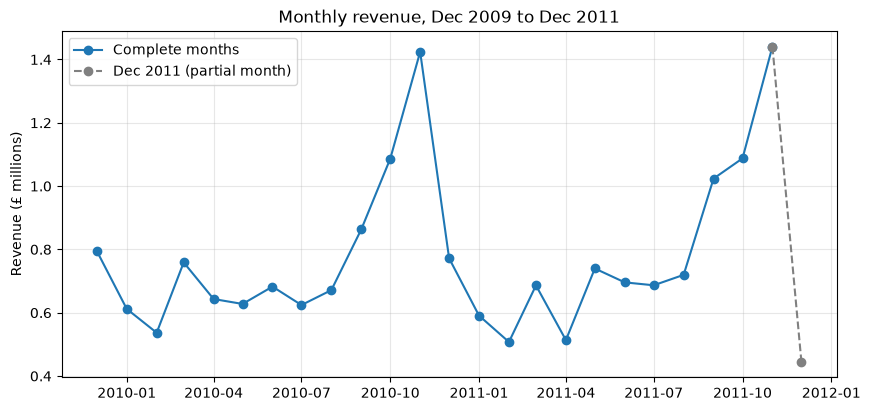

In [8]:
import matplotlib.pyplot as plt
from pathlib import Path

m = monthly.copy()
m["month"] = pd.to_datetime(m["month"])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(m["month"].iloc[:-1], m["revenue"].iloc[:-1] / 1e6, marker="o", label="Complete months")
ax.plot(m["month"].iloc[-2:], m["revenue"].iloc[-2:] / 1e6, linestyle="--", marker="o",
        color="grey", label="Dec 2011 (partial month)")
ax.set_title("Monthly revenue, Dec 2009 to Dec 2011")
ax.set_ylabel("Revenue (£ millions)")
ax.legend()
ax.grid(alpha=0.3)

Path("../figures").mkdir(exist_ok=True)
fig.savefig("../figures/monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
q3 = """
SELECT i.country,
       COUNT(*)                   AS orders,
       ROUND(AVG(order_total), 0) AS avg_order_value
FROM (
    SELECT invoice_no, SUM(revenue) AS order_total
    FROM invoice_lines
    GROUP BY invoice_no
) t
JOIN invoices i ON i.invoice_no = t.invoice_no
GROUP BY i.country
HAVING orders >= 50
ORDER BY avg_order_value DESC
LIMIT 10;
"""
display(pd.read_sql_query(q3, con))

order_totals = sales.groupby("Invoice").agg(total=("Revenue", "sum"), country=("Country", "first"))
order_totals.groupby("country")["total"].median().round(0)[["United Kingdom", "Netherlands", "EIRE", "Germany", "France"]]

,country,orders,avg_order_value
0,Netherlands,216,2545.0
1,Australia,85,1970.0
2,Switzerland,82,1142.0
3,EIRE,578,1063.0
4,Sweden,98,878.0
5,Channel Islands,53,814.0
6,Spain,144,679.0
7,Portugal,84,562.0
8,France,595,521.0
9,Germany,753,509.0


country
United Kingdom    295.0
Netherlands       657.0
EIRE              689.0
Germany           360.0
France            359.0
Name: total, dtype: float64

In [10]:
Path("../sql").mkdir(exist_ok=True)
Path("../sql/01_monthly_revenue.sql").write_text(q1)
Path("../sql/02_revenue_by_country.sql").write_text(q2)
Path("../sql/03_order_value_by_country.sql").write_text(q3)

352

In [11]:
cust_rev = (
    sales.dropna(subset=["Customer ID"])
    .groupby(["Country", "Customer ID"])["Revenue"].sum()
    .reset_index()
)

rows = []
for c in ["United Kingdom", "Netherlands", "EIRE", "Germany", "France"]:
    s = cust_rev[cust_rev["Country"] == c]["Revenue"].sort_values(ascending=False)
    rows.append({
        "country": c,
        "customers": len(s),
        "top_customer_share_pct": round(100 * s.iloc[0] / s.sum(), 1),
    })
pd.DataFrame(rows)

,country,customers,top_customer_share_pct
0,United Kingdom,5332,4.2
1,Netherlands,22,95.8
2,EIRE,3,52.3
3,Germany,107,9.1
4,France,93,10.6


In [12]:
chk = sales[sales["Country"].isin(["Netherlands", "EIRE"])]
pd.DataFrame({
    "rows_missing_id_pct": chk.groupby("Country")["Customer ID"].apply(lambda s: round(100 * s.isna().mean(), 1)),
    "revenue_missing_id_pct": chk.groupby("Country").apply(
        lambda g: round(100 * g.loc[g["Customer ID"].isna(), "Revenue"].sum() / g["Revenue"].sum(), 1)
    ),
})


,rows_missing_id_pct,revenue_missing_id_pct
Country,,
EIRE,9.3,6.0
Netherlands,0.0,0.0
